### TULIKA KEWLANI
### B1-B2-21

### TOPIC:Statistical Analysis and Prediction of Household Electricity Consumption

### WEB SCRAPPING
Objective: Extract electricity demand information from the MSEDCL website using Requests, BeautifulSoup and Pandas.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://www.mahadiscom.in/en/msedcl-peak-demand-en/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print("Status:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")

print("Number of tables:", len(tables))

Status: 200
Number of tables: 1


In [2]:
table = tables[0]

rows = []

for row in table.find_all("tr"):
    cells = row.find_all(["th", "td"])
    cells = [cell.get_text(" ", strip=True) for cell in cells]

    if cells:
        rows.append(cells)

scraped_df = pd.DataFrame(rows)

print(scraped_df)

                      0      1           2           3           4
0                 Field  Value        Date  Updated On  Updated by
1        DEMAND_CATERED  27655  2026-10-24  2026-10-25     lmkalwa
2  DEMAND_CATERED_MONTH  28221  2026-10-10  2026-10-25     lmkalwa
3   DEMAND_CATERED_YEAR  28221  2026-10-10  2026-10-25     lmkalwa
4   DEMAND_CATERED_TILL  28221  2026-10-10  2026-10-25     lmkalwa
5          MORNING_PEAK  26504  2026-10-24  2026-10-25     lmkalwa
6              DAY_PEAK  27655  2026-10-24  2026-10-25     lmkalwa
7          EVENING_PEAK  24898  2026-10-24  2026-10-25     lmkalwa
8         NIGHT_MINIMUM  23019  2026-10-24  2026-10-25     lmkalwa


In [3]:
import pandas as pd

url = "https://www.mahadiscom.in/en/msedcl-peak-demand-en/"

tables = pd.read_html(url)

print("Tables found:", len(tables))

for i, table in enumerate(tables):
    print("\nTable", i)
    print(table.head())

Tables found: 1

Table 0
                  Field  Value        Date  Updated On Updated by
0        DEMAND_CATERED  27655  2026-10-24  2026-10-25    lmkalwa
1  DEMAND_CATERED_MONTH  28221  2026-10-10  2026-10-25    lmkalwa
2   DEMAND_CATERED_YEAR  28221  2026-10-10  2026-10-25    lmkalwa
3   DEMAND_CATERED_TILL  28221  2026-10-10  2026-10-25    lmkalwa
4          MORNING_PEAK  26504  2026-10-24  2026-10-25    lmkalwa


### DATA LOADING,CLEANING AND DESCRIPTIVE STATISTICS
Objective: Load the household electricity dataset, handle missing values and calculate mean, median, variance, standard deviation, minimum and maximum consumption.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/household_power_consumption.csv")

print(df.head())
print(df.shape)
print(df.columns)

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  01/01/2007  00:00:00                1.069                  0.144   236.03   
1  01/01/2007  01:00:00                1.479                  0.037   238.54   
2  01/01/2007  02:00:00                1.361                  0.180   241.26   
3  01/01/2007  03:00:00                1.249                  0.195   239.69   
4  01/01/2007  04:00:00                0.992                  0.000   238.05   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              4.11            0.34            5.26           11.89  
1              6.96            0.89            4.93           14.29  
2              5.56            3.04            5.71           18.24  
3              3.60            3.79           16.39           22.32  
4              3.27            0.25            7.60           24.03  
(1200, 9)
Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 

In [5]:
df = df.replace("?", np.nan)

for col in df.columns:
    if col not in ["Date", "Time"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

print(df.isnull().sum())
print(df.shape)

Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
(1200, 9)


In [6]:
power = df["Global_active_power"]

print("Mean:", power.mean())
print("Median:", power.median())
print("Variance:", power.var())
print("Standard Deviation:", power.std())
print("Minimum:", power.min())
print("Maximum:", power.max())

Mean: 1.2330199999999998
Median: 1.238
Variance: 0.09374984113427863
Standard Deviation: 0.3061859584211507
Minimum: 0.188
Maximum: 2.201


### DATA VISUALIZATION AND CENTRAL LIMIT THEOREM
Objective: Visualize electricity consumption patterns using graphs and demonstrate the Central Limit Theorem through sampling.

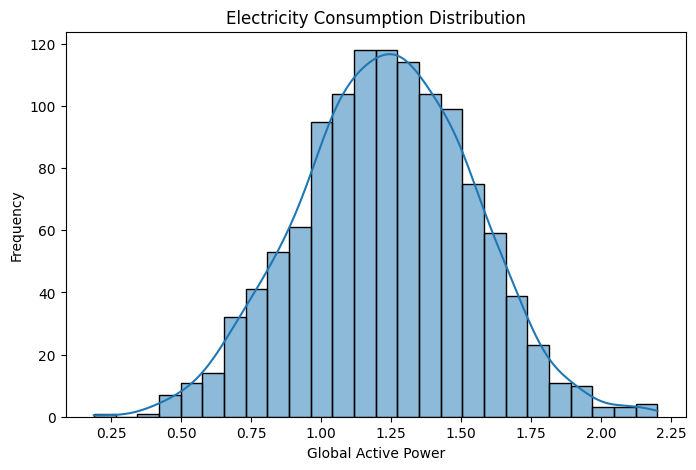

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(power, kde=True)

plt.title("Electricity Consumption Distribution")
plt.xlabel("Global Active Power")
plt.ylabel("Frequency")

plt.show()

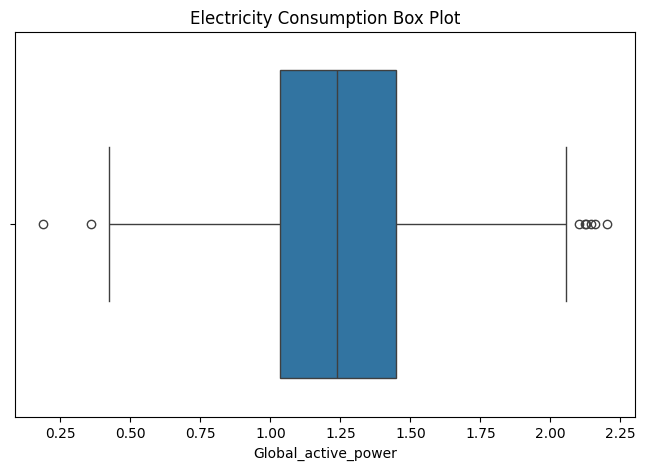

In [8]:
plt.figure(figsize=(8,5))

sns.boxplot(x=power)

plt.title("Electricity Consumption Box Plot")

plt.show()

In [9]:
sample_means = []

for i in range(1000):
    sample = power.sample(30)
    sample_means.append(sample.mean())

print("Population Mean:", power.mean())
print("Mean of Sample Means:", np.mean(sample_means))

Population Mean: 1.2330199999999998
Mean of Sample Means: 1.230872566666667


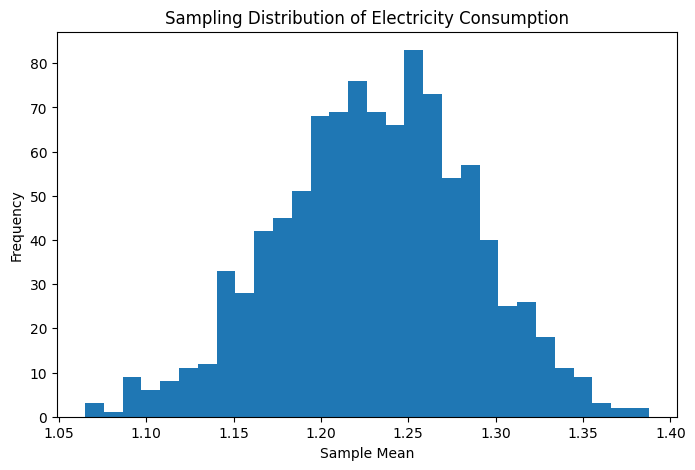

In [10]:
plt.figure(figsize=(8,5))

plt.hist(sample_means, bins=30)

plt.title("Sampling Distribution of Electricity Consumption")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.show()

### LOGISTIC REGRESSION CLASSIFICATION
Objective: Apply logistic regression to classify electricity consumption into categories and evaluate model performance.

In [11]:
median_power = df["Global_active_power"].median()

df["Consumption_Level"] = np.where(
    df["Global_active_power"] >= median_power,
    "High",
    "Low"
)

print(df["Consumption_Level"].value_counts())

Consumption_Level
High    602
Low     598
Name: count, dtype: int64


In [12]:
X = df[[
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]]

y = df["Consumption_Level"]

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [14]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="High"))
print("Recall:", recall_score(y_test, y_pred, pos_label="High"))
print("F1 Score:", f1_score(y_test, y_pred, pos_label="High"))

Accuracy: 0.8333333333333334
Precision: 0.8540145985401459
Recall: 0.8540145985401459
F1 Score: 0.8540145985401459


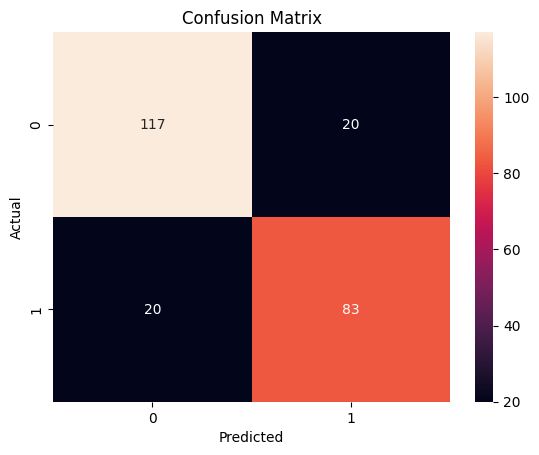

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [17]:
X = df[[
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]]

y = df["Global_active_power"]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [19]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()

reg.fit(X_train, y_train)

y_pred = reg.predict(X_test)

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.12816548903024869
MSE: 0.025010731660063106
RMSE: 0.1581478158561259
R2 Score: 0.6990143135791813


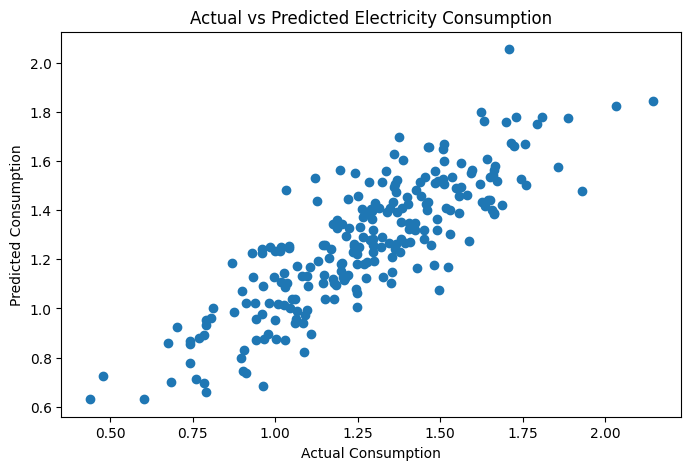

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Actual vs Predicted Electricity Consumption")

plt.show()

In [22]:
sample = X_test.iloc[[0]]

prediction = reg.predict(sample)

print("Predicted Consumption:", prediction[0])
print("Actual Consumption:", y_test.iloc[0])

Predicted Consumption: 1.3321245438192448
Actual Consumption: 1.257


In [23]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 36.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 72.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


### CONFIDENCE INTERVALS AND HYPOTHESIS TESTING
Objective: Calculate confidence intervals and perform statistical hypothesis tests to draw conclusions about electricity consumption.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.weightstats import ztest

In [25]:
power = df["Global_active_power"].dropna()

n = len(power)
mean = power.mean()
std = power.std()
sem = stats.sem(power)

confidence = 0.95

ci = stats.t.interval(
    confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

print("Sample Size:", n)
print("Mean:", mean)
print("Standard Deviation:", std)
print("95% Confidence Interval:", ci)

Sample Size: 1200
Mean: 1.2330199999999998
Standard Deviation: 0.3061859584211507
95% Confidence Interval: (np.float64(1.2156787115207102), np.float64(1.2503612884792894))


In [26]:
hypothesized_mean = 1.0

t_stat, p_value = stats.ttest_1samp(
    power,
    popmean=hypothesized_mean
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

T-statistic: 26.363225881479185
P-value: 3.464274576599807e-121
Reject Null Hypothesis


In [27]:
population_mean = 1.0
population_std = 1.2

z_stat = (mean - population_mean) / (
    population_std / np.sqrt(n)
)

p_value = 2 * stats.norm.sf(abs(z_stat))

print("Z-statistic:", z_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Z-statistic: 6.726707986328325
P-value: 1.7354452358706567e-11
Reject Null Hypothesis


### CHI-SQUARE TEST AND TWO-WAY ANOVA
Objective: Apply the Chi-Square test to examine associations between categorical variables and Two-Way ANOVA to study the effects of two factors.

In [28]:
from scipy.stats import chi2_contingency

df["Consumption_Level"] = np.where(
    df["Global_active_power"] >=
    df["Global_active_power"].median(),
    "High",
    "Low"
)

df["Hour"] = pd.to_datetime(
    df["Time"], format="%H:%M:%S", errors="coerce"
).dt.hour

df["Time_Group"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

contingency_table = pd.crosstab(
    df["Time_Group"],
    df["Consumption_Level"]
)

print("Contingency Table:")
print(contingency_table)

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p)
print("Expected Frequencies:\n", expected)

if p < 0.05:
    print("Reject Null Hypothesis: Variables are associated")
else:
    print("Fail to Reject Null Hypothesis")

Contingency Table:
Consumption_Level  High  Low
Time_Group                  
Night               156  144
Morning             156  144
Afternoon           149  151
Evening             141  159
Chi-square Statistic: 2.0400226669185217
Degrees of Freedom: 3
P-value: 0.5641415418792328
Expected Frequencies:
 [[150.5 149.5]
 [150.5 149.5]
 [150.5 149.5]
 [150.5 149.5]]
Fail to Reject Null Hypothesis


In [29]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    errors="coerce"
)

df["Day"] = df["DateTime"].dt.day_name()

anova_data = df[
    ["Global_active_power", "Time_Group", "Day"]
].dropna().copy()

# Use a reproducible sample to keep computation manageable
if len(anova_data) > 20000:
    anova_data = anova_data.sample(
        20000, random_state=42
    )

model = ols(
    "Q('Global_active_power') ~ C(Time_Group) * C(Day)",
    data=anova_data
).fit()

anova_results = anova_lm(model, typ=2)

print("Two-Way ANOVA Results:")
print(anova_results)

Two-Way ANOVA Results:
                         sum_sq     df         F    PR(>F)
C(Time_Group)          0.253769    3.0  0.882729  0.449791
C(Day)                 0.418534    6.0  0.727930  0.627260
C(Time_Group):C(Day)   1.781967   18.0  1.033089  0.419854
Residual              52.513404  548.0       NaN       NaN


### COVARIANCE AND CORRELATION ANALYSIS
Objective: Calculate covariance and correlation to analyze relationships between household electricity consumption variables.

In [30]:
x = df["Global_active_power"]
y = df["Global_intensity"]

print("Covariance:", x.cov(y))
print("Pearson Correlation:", x.corr(y, method="pearson"))
print("Spearman Correlation:", x.corr(y, method="spearman"))

Covariance: 0.4692321894912428
Pearson Correlation: 0.7748165315375599
Spearman Correlation: 0.76412511487762


In [31]:
pearson_r, pearson_p = stats.pearsonr(x, y)

print("Pearson Correlation:", pearson_r)
print("P-value:", pearson_p)

if pearson_p < 0.05:
    print("Significant correlation")
else:
    print("No statistically significant correlation")

Pearson Correlation: 0.7748165315375598
P-value: 7.6819819742921e-241
Significant correlation


In [32]:
spearman_r, spearman_p = stats.spearmanr(x, y)

print("Spearman Correlation:", spearman_r)
print("P-value:", spearman_p)

if spearman_p < 0.05:
    print("Significant monotonic relationship")
else:
    print("No statistically significant monotonic relationship")

Spearman Correlation: 0.76412511487762
P-value: 2.4357831098906966e-230
Significant monotonic relationship


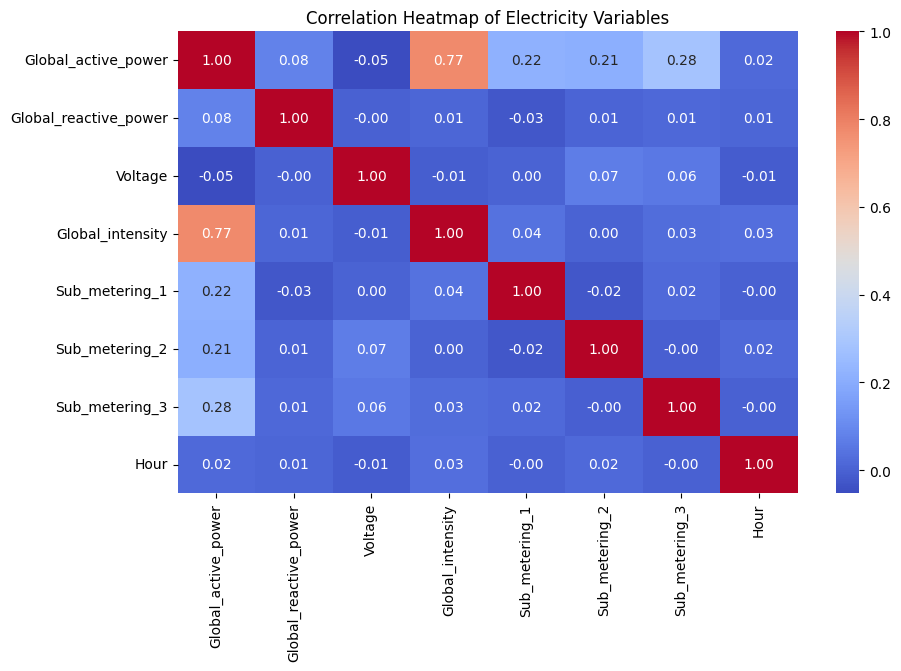

In [33]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Electricity Variables")
plt.show()

### MACHINE LEARNING: CLASSIFICATION AND REGRESSION
Objective: Build and evaluate machine learning classification and regression models to analyze and predict household electricity consumption.

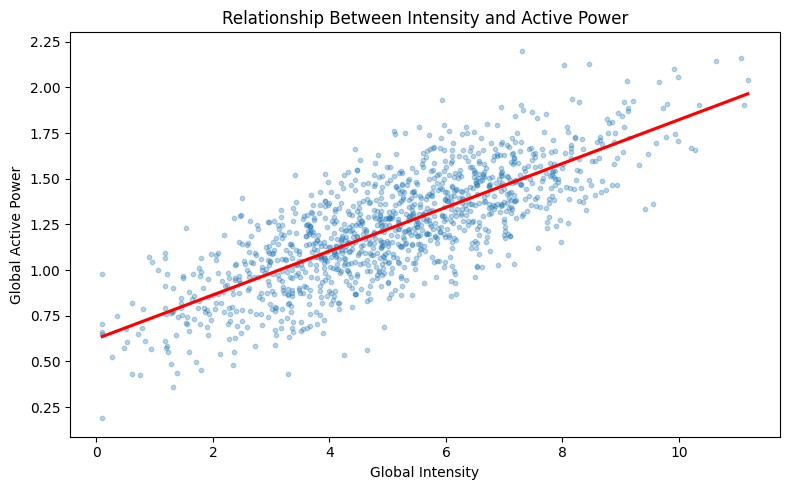

In [34]:


plot_df = df[
    ["Global_intensity", "Global_active_power"]
].dropna()

if len(plot_df) > 5000:
    plot_df = plot_df.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))

sns.regplot(
    data=plot_df,
    x="Global_intensity",
    y="Global_active_power",
    ci=None,
    scatter_kws={"alpha": 0.3, "s": 10},
    line_kws={"color": "red"}
)

plt.xlabel("Global Intensity")
plt.ylabel("Global Active Power")
plt.title("Relationship Between Intensity and Active Power")
plt.tight_layout()
plt.show()


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

df["Consumption_Level"] = np.where(
    df["Global_active_power"] >=
    df["Global_active_power"].median(),
    "High",
    "Low"
)

features = [
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

data = df[features + ["Consumption_Level"]].dropna()

X = data[features]
y = data["Consumption_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, pos_label="High", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, pos_label="High", zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred, pos_label="High", zero_division=0
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8583333333333333
Precision: 0.8583333333333333
Recall: 0.8583333333333333
F1 Score: 0.8583333333333333

Classification Report:
              precision    recall  f1-score   support

        High       0.86      0.86      0.86       120
         Low       0.86      0.86      0.86       120

    accuracy                           0.86       240
   macro avg       0.86      0.86      0.86       240
weighted avg       0.86      0.86      0.86       240



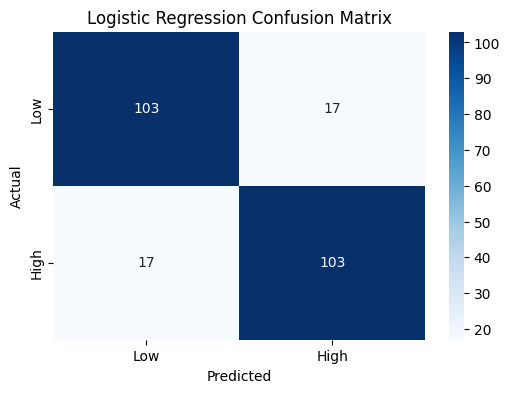

In [36]:
cm = confusion_matrix(
    y_test, y_pred,
    labels=["Low", "High"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "High"],
    yticklabels=["Low", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [37]:
sample = X_test.iloc[[0]]

prediction = clf.predict(sample)

print("Input Measurements:")
print(sample)

print("Predicted Consumption Level:", prediction[0])
print("Actual Consumption Level:", y_test.iloc[0])

Input Measurements:
     Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  \
851                  0.081   236.33              4.91            1.27   

     Sub_metering_2  Sub_metering_3  
851            6.78            9.77  
Predicted Consumption Level: Low
Actual Consumption Level: Low


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

reg_features = [
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

reg_data = df[
    reg_features + ["Global_active_power"]
].dropna()

X = reg_data[reg_features]
y = reg_data["Global_active_power"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

reg = LinearRegression()
reg.fit(X_train, y_train)

y_pred = reg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.12816548903024869
MSE: 0.025010731660063106
RMSE: 0.1581478158561259
R2 Score: 0.6990143135791813


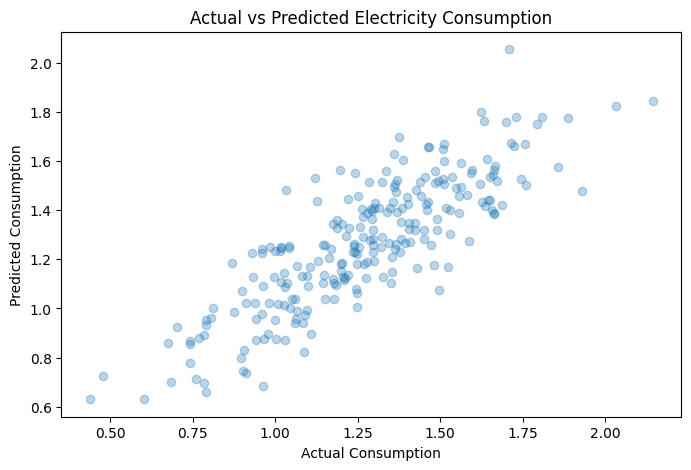

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Actual vs Predicted Electricity Consumption")

plt.show()

In [40]:
sample = X_test.iloc[[0]]

prediction = reg.predict(sample)

print("Predicted Active Power:", prediction[0], "kW")
print("Actual Active Power:", y_test.iloc[0], "kW")

Predicted Active Power: 1.3321245438192448 kW
Actual Active Power: 1.257 kW


In [45]:
!pip install -q streamlit plotly scipy scikit-learn pandas numpy

In [72]:
import shutil

shutil.copy(
    "/content/electricity_dashboard_report_style_v3.py",
    "/content/app.py"
)

!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [73]:
from google.colab.output import eval_js
import time

time.sleep(5)
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-gpu-t4-s-usw1b2-9gnpfb3xuyuk-b.us-west1.prod.r.colab.dev
